# Proyecto Integrador de Ciencia de Datos
## Fase 1 — Planteamiento del problema y Análisis Exploratorio de Datos (EDA)

**Autores:** Harold Andrés Horta Suárez, Anderson Alexander González Ruiz
**Dataset:** Seoul Bike Sharing Demand (UCI Machine Learning Repository)

### Contexto
Los sistemas de bicicletas compartidas (*bike-sharing*) se han vuelto una pieza central de la movilidad urbana en ciudades densas: ofrecen una alternativa de bajo costo y bajas emisiones para trayectos cortos, pero su operación depende de un problema logístico difícil — distribuir la cantidad correcta de bicicletas en cada estación y en cada momento del día. Si faltan bicicletas en horas pico, el sistema pierde usuarios frente a otros medios de transporte; si sobran, la ciudad incurre en costos de mantenimiento y redistribución innecesarios. Seúl opera uno de los sistemas públicos de bicicletas más grandes de Asia, y el dataset analizado aquí registra, hora a hora durante un año completo, cuántas bicicletas se alquilaron junto con las condiciones climáticas y de calendario de ese momento.

### Pregunta de investigación
**Principal:** ¿En qué medida las condiciones climáticas y temporales (hora del día, estación del año, día festivo) permiten predecir y explicar la demanda horaria de bicicletas compartidas en Seúl?

**Secundarias:**
1. ¿Qué variables climáticas presentan la asociación más fuerte con la demanda horaria? *(regresión)*
2. ¿Es posible inferir la estación del año a partir del patrón climático y de demanda observado en una hora determinada? *(clasificación)*
3. ¿Existen perfiles horarios de condiciones climáticas (clústeres) con niveles de demanda claramente distintos entre sí, útiles para decisiones operativas de redistribución de flota? *(clustering)*

### Objetivos
**General:** Desarrollar un modelo analítico integral que permita predecir la demanda horaria de bicicletas compartidas en Seúl a partir de variables climáticas y temporales, como insumo para decisiones de distribución de flota.

**Específicos (SMART):**
1. Construir un modelo de regresión que explique al menos el 70% de la varianza (R²) de la demanda horaria de bicicletas a partir de variables climáticas y temporales, evaluado sobre un conjunto de prueba independiente.
2. Entrenar y comparar al menos dos algoritmos de clasificación capaces de predecir la estación del año a partir de las condiciones horarias, con una exactitud (*accuracy*) superior al 80% sobre el conjunto de prueba.
3. Identificar, mediante al menos dos algoritmos de clustering, entre 3 y 5 perfiles horarios de condiciones climáticas con niveles de demanda significativamente distintos entre sí (ANOVA, p < 0.05).

## 1. Ficha técnica del dataset y carga de datos

| Campo | Valor |
|---|---|
| Nombre | Seoul Bike Sharing Demand |
| Repositorio de origen | UCI Machine Learning Repository |
| URL exacta | https://archive.ics.uci.edu/dataset/560/seoul+bike+sharing+demand |
| DOI | 10.24432/C5F62R |
| Fecha de extracción | 12 de noviembre de 2026 |
| Licencia | Creative Commons Attribution 4.0 International (CC BY 4.0) |
| Año de creación del dataset | 2020 (datos del periodo dic. 2017 – nov. 2018) |
| Filas | 8760 (una por cada hora del año) |
| Columnas | 14 |
| Valores faltantes reportados por UCI | 0% |

**Nota técnica:** el archivo CSV crudo de UCI viene en encoding `cp1252` (no UTF-8) porque fue exportado originalmente desde una herramienta que usa esa codificación — si lo cargás con `utf-8` a secas, Python te va a tirar un `UnicodeDecodeError` apenas intente leer el símbolo de grados (°). Esto es un detalle de bajo nivel pero típico: **nunca asumas la codificación de un archivo que no generaste vos mismo**, siempre verificala primero.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [2]:
df = pd.read_csv("../data/raw/SeoulBikeData.csv", encoding="cp1252")
df.shape

(8760, 14)

Los nombres de columna originales traen espacios y unidades embebidas (`"Wind speed (m/s)"`, `"Temperature(°C)"`). Eso funciona para mostrar en una tabla, pero es incómodo y propenso a errores en código (no podés escribir `df.Wind speed` como atributo). Renombramos a `snake_case` sin unidades — la unidad queda documentada en el diccionario de datos, no en el nombre de la columna.

In [3]:
df = df.rename(columns={
    "Rented Bike Count": "Rented_Bike_Count",
    "Temperature(°C)": "Temperature",
    "Humidity(%)": "Humidity",
    "Wind speed (m/s)": "Wind_speed",
    "Visibility (10m)": "Visibility",
    "Dew point temperature(°C)": "Dew_point_temp",
    "Solar Radiation (MJ/m2)": "Solar_Radiation",
    "Rainfall(mm)": "Rainfall",
    "Snowfall (cm)": "Snowfall",
    "Functioning Day": "Functioning_Day",
})

cols_preview = ["Date", "Hour", "Rented_Bike_Count", "Temperature", "Seasons", "Holiday"]
df[cols_preview].head(3)

,Date,Hour,Rented_Bike_Count,Temperature,Seasons,Holiday
0,01/12/2017,0,254,-5.2,Winter,No Holiday
1,01/12/2017,1,204,-5.5,Winter,No Holiday
2,01/12/2017,2,173,-6.0,Winter,No Holiday


### 1.1 Diccionario de datos

| Variable | Tipo | Descripción | Rango / valores |
|---|---|---|---|
| Date | Fecha | Fecha de la observación | 01-dic-2017 a 30-nov-2018 |
| Rented_Bike_Count | Cuantitativa continua | Cantidad de bicicletas alquiladas en esa hora | 0 – 3556 |
| Hour | Cuantitativa discreta | Hora del día | 0 – 23 |
| Temperature | Cuantitativa continua | Temperatura del aire (°C) | -17.8 – 39.4 |
| Humidity | Cuantitativa discreta | Humedad relativa (%) | 0 – 98 |
| Wind_speed | Cuantitativa continua | Velocidad del viento (m/s) | 0 – 7.4 |
| Visibility | Cuantitativa discreta | Visibilidad (unidades de 10m) | 27 – 2000 |
| Dew_point_temp | Cuantitativa continua | Punto de rocío (°C) | -30.6 – 27.2 |
| Solar_Radiation | Cuantitativa continua | Radiación solar (MJ/m²) | 0 – 3.52 |
| Rainfall | Cuantitativa continua | Precipitación (mm) | 0 – 35 |
| Snowfall | Cuantitativa continua | Nevada (cm) | 0 – 8.8 |
| Seasons | Cualitativa nominal | Estación del año | Spring, Summer, Autumn, Winter |
| Holiday | Cualitativa nominal | Si la fecha es festivo | Holiday, No Holiday |
| Functioning_Day | Cualitativa nominal | Si el sistema estaba operativo esa hora | Yes, No |

Con esto ya tenemos los tres objetivos de modelado cubiertos por el mismo dataset: **`Rented_Bike_Count`** es la variable continua para regresión, **`Seasons`** es la variable categórica para clasificación, y el bloque de variables climáticas (`Temperature`, `Humidity`, `Wind_speed`, `Solar_Radiation`, etc.) es el insumo para clustering.

## 2. Análisis Exploratorio de Datos (EDA)

### 2.1 Análisis univariado

Acá miramos cada variable **sola**, antes de buscar relaciones entre ellas. Dos estadísticos que vamos a mirar con cuidado:

- **Asimetría (*skewness*):** mide si la distribución es simétrica (≈0) o si tiene una cola larga hacia un lado. Una asimetría alta te avisa que la media va a estar distorsionada por valores extremos, y que quizás necesites una transformación (log, por ejemplo) antes de meter la variable en un modelo lineal.
- **Curtosis:** mide qué tan "pesadas" son las colas comparadas con una normal. Curtosis muy alta = hay eventos raros pero extremos (outliers reales, no errores).

No alcanza con calcular los números — hay que interpretarlos en el contexto del problema, por eso cada bloque de código va seguido de una celda de interpretación.

In [5]:
num_cols = ["Rented_Bike_Count", "Hour", "Temperature", "Humidity", "Wind_speed",
            "Visibility", "Dew_point_temp", "Solar_Radiation", "Rainfall", "Snowfall"]

resumen = pd.DataFrame({
    "media": df[num_cols].mean(),
    "mediana": df[num_cols].median(),
    "moda": df[num_cols].mode().iloc[0],
    "varianza": df[num_cols].var(),
    "desv_std": df[num_cols].std(),
    "asimetria": df[num_cols].skew(),
    "curtosis": df[num_cols].kurt(),
}).round(2)
resumen

,media,mediana,moda,varianza,desv_std,asimetria,curtosis
Rented_Bike_Count,704.60,504.50,0.0,416021.73,645.00,1.15,0.85
Hour,11.50,11.50,0.0,47.92,6.92,0.00,-1.20
Temperature,12.88,13.70,19.1,142.68,11.94,-0.20,-0.84
Humidity,58.23,57.00,53.0,414.63,20.36,0.06,-0.80
Wind_speed,1.72,1.50,1.1,1.07,1.04,0.89,0.73
Visibility,1436.83,1698.00,2000.0,370027.32,608.30,-0.70,-0.96
Dew_point_temp,4.07,5.10,0.0,170.57,13.06,-0.37,-0.76
Solar_Radiation,0.57,0.01,0.0,0.75,0.87,1.50,1.13
Rainfall,0.15,0.00,0.0,1.27,1.13,14.53,284.99
Snowfall,0.08,0.00,0.0,0.19,0.44,8.44,93.80


**Interpretación:** `Rainfall` y `Snowfall` tienen una asimetría extrema (14.53 y 8.44) con curtosis altísima (285 y 94) — esto es consistente con variables que valen cero la gran mayoría de las horas y solo ocasionalmente registran un evento de lluvia o nieve: no son variables continuas "normales", son esencialmente **variables de evento raro**. `Rented_Bike_Count`, nuestra variable objetivo de regresión, tiene una asimetría moderada hacia la derecha (1.15): hay muchas horas de demanda baja (de madrugada) y relativamente pocas de demanda muy alta, pero no al extremo de lluvia/nieve. Esto ya nos avisa que en la Fase 2 probablemente convenga aplicar una transformación logarítmica a la variable objetivo antes de entrenar modelos lineales.

In [6]:
for col in ["Seasons", "Holiday", "Functioning_Day"]:
    print(f"--- {col} ---")
    print(df[col].value_counts())
    print()

--- Seasons ---
Seasons
Spring    2208
Summer    2208
Autumn    2184
Winter    2160
Name: count, dtype: int64

--- Holiday ---
Holiday
No Holiday    8328
Holiday        432
Name: count, dtype: int64

--- Functioning_Day ---
Functioning_Day
Yes    8465
No      295
Name: count, dtype: int64



**Interpretación:** `Seasons` está perfectamente balanceada entre las cuatro categorías (2160-2208 observaciones cada una), lo cual es ideal para nuestro problema de clasificación: no hace falta ninguna técnica de balanceo de clases para esa tarea. `Holiday`, en cambio, está fuertemente desbalanceada (432 horas festivas contra 8328 no festivas, 4.9%), y `Functioning_Day` también (295 horas sin servicio contra 8465 en operación, 3.4%) — pero ninguna de las dos se usa como variable objetivo en este proyecto, así que ese desbalance no exige corrección en esta fase.

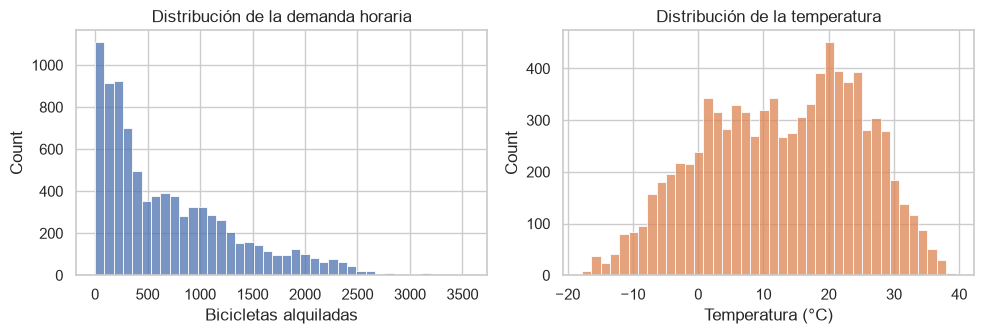

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
sns.histplot(df["Rented_Bike_Count"], bins=40, ax=axes[0], color="#4C72B0")
axes[0].set_title("Distribución de la demanda horaria")
axes[0].set_xlabel("Bicicletas alquiladas")
sns.histplot(df["Temperature"], bins=40, ax=axes[1], color="#DD8452")
axes[1].set_title("Distribución de la temperatura")
axes[1].set_xlabel("Temperatura (°C)")
plt.tight_layout()
plt.show()

### 2.2 Análisis bivariado y multivariado

Acá pasamos de "¿cómo se comporta cada variable?" a "¿cómo se mueven las variables JUNTAS?". Tres herramientas:

- **Matriz de correlación (Pearson):** mide asociación lineal entre pares de variables cuantitativas, de -1 a 1. Útil para detectar qué variables van a aportar señal al modelo de regresión, y también para detectar **multicolinealidad** (dos variables que miden casi lo mismo, lo cual infla la varianza de los coeficientes en una regresión lineal).
- **Scatter plot:** complementa la correlación porque la correlación de Pearson solo capta relaciones *lineales* — un scatter te deja ver si la relación real es curva, o si depende de un tercer factor (acá vamos a cruzar con `Seasons`).
- **Prueba χ² (chi-cuadrado) de independencia:** la correlación de Pearson es para variables numéricas; para ver si dos variables **categóricas** están relacionadas entre sí (por ejemplo, ¿la estación del año influye en si un día es festivo?) usamos esta prueba de hipótesis.

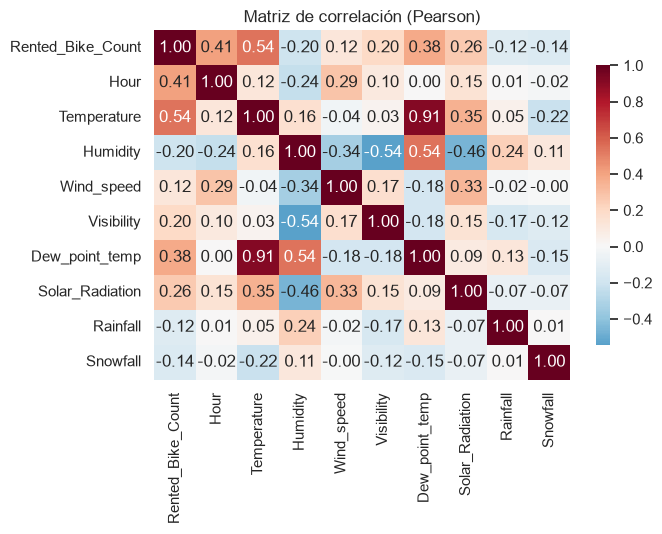

In [8]:
corr = df[num_cols].corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(
    corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax,
    cbar_kws={"shrink": 0.8}
)
ax.set_title("Matriz de correlación (Pearson)")
plt.tight_layout()
plt.show()

**Interpretación:** la demanda de bicicletas (`Rented_Bike_Count`) correlaciona más fuerte con `Temperature` (r = 0.54) y con `Hour` (r = 0.41): hace más calor, más gente pedalea, y hay horas del día con mucho más tráfico (hora pico) que otras. `Humidity` (r = -0.20), `Rainfall` (r = -0.12) y `Snowfall` (r = -0.14) correlacionan negativamente, como era de esperar: nadie elige la bicicleta bajo lluvia o nieve. También se observa una correlación muy alta entre `Temperature` y `Dew_point_temp` (r = 0.91, ambas miden fenómenos térmicos relacionados), señal de **multicolinealidad** a tener en cuenta cuando entrenemos modelos de regresión múltiple en la Fase 3 — probablemente convenga no usar las dos a la vez en un modelo lineal.

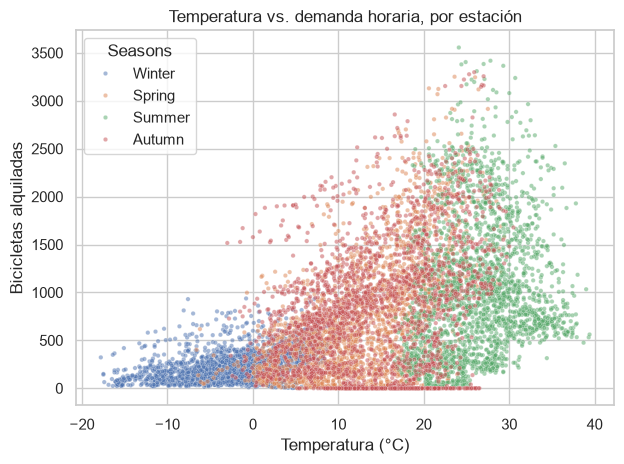

In [9]:
fig, ax = plt.subplots()
sns.scatterplot(
    data=df, x="Temperature", y="Rented_Bike_Count",
    hue="Seasons", s=10, alpha=0.5, ax=ax
)
ax.set_title("Temperatura vs. demanda horaria, por estación")
ax.set_xlabel("Temperatura (°C)")
ax.set_ylabel("Bicicletas alquiladas")
plt.tight_layout()
plt.show()

**Interpretación:** la relación entre temperatura y demanda no es una sola línea recta global, sino que cada estación ocupa su propia banda de temperaturas: invierno (temperaturas bajas, demanda baja) y verano (temperaturas altas, demanda alta) se separan con claridad. Esto sugiere que un modelo de regresión que use `Temperature` junto con `Seasons` va a capturar mejor el fenómeno que uno que use solo la temperatura — es la justificación empírica de por qué en la Fase 2 vamos a necesitar variables categóricas codificadas, no solo las numéricas.

In [10]:
tabla_cruzada = pd.crosstab(df["Seasons"], df["Holiday"])
chi2, p, dof, _ = stats.chi2_contingency(tabla_cruzada)
print(tabla_cruzada)
print(f"\nChi2 = {chi2:.2f}, p-valor = {p:.2e}, grados de libertad = {dof}")

Holiday  Holiday  No Holiday
Seasons                     
Autumn       120        2064
Spring        72        2136
Summer        48        2160
Winter       192        1968

Chi2 = 122.59, p-valor = 2.14e-26, grados de libertad = 3


**Interpretación:** la prueba de independencia chi-cuadrado rechaza con total contundencia (p < 0.0001) la hipótesis de que `Seasons` y `Holiday` son independientes. Tiene sentido: Corea del Sur concentra festivos largos en invierno (como el Año Nuevo Lunar), por lo que esa estación acumula casi el doble de horas festivas que las demás (192 vs. ~48-120 en las otras). Es una relación de calendario, no una casualidad estadística, pero conviene tenerla presente para no confundir el efecto de "ser festivo" con el efecto de "ser invierno" al interpretar modelos futuros.

### 2.3 Diagnóstico de calidad de datos

Tres chequeos obligatorios antes de confiar en cualquier dataset:

1. **Valores faltantes** por variable — si hay, hay que decidir *por qué* faltan antes de imputar (eso lo trabajamos recién en la Fase 2, con el marco MCAR/MAR/MNAR).
2. **Outliers** vía la regla del rango intercuartílico (IQR): todo lo que cae por fuera de `[Q1 - 1.5·IQR, Q3 + 1.5·IQR]` se marca como atípico. No significa "error" — significa "merece revisión".
3. **Incoherencias lógicas**: filas duplicadas, o combinaciones de variables que no tienen sentido de negocio (por ejemplo, demanda > 0 en una hora donde el sistema estaba cerrado).

In [11]:
print("% de valores faltantes por variable:")
print((df.isna().mean() * 100).round(2))
print("\nFilas duplicadas:", df.duplicated().sum())

% de valores faltantes por variable:
Date                 0.0
Rented_Bike_Count    0.0
Hour                 0.0
Temperature          0.0
Humidity             0.0
Wind_speed           0.0
Visibility           0.0
Dew_point_temp       0.0
Solar_Radiation      0.0
Rainfall             0.0
Snowfall             0.0
Seasons              0.0
Holiday              0.0
Functioning_Day      0.0
dtype: float64

Filas duplicadas: 0


**Interpretación — valores faltantes:** tanto el diagnóstico propio como la ficha oficial de UCI coinciden en 0% de valores faltantes en las 14 variables. Siguiendo el marco MCAR/MAR/MNAR: no aplica ningún mecanismo de dato faltante porque no hay ningún dato faltante que explicar — es un resultado genuino del diagnóstico, no una omisión. No se requiere imputación en este dataset.

In [12]:
q1, q3 = df["Rented_Bike_Count"].quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = df[(df["Rented_Bike_Count"] < lim_inf) | (df["Rented_Bike_Count"] > lim_sup)]
print(f"Límites IQR: [{lim_inf:.1f}, {lim_sup:.1f}]")
pct_outliers = len(outliers) / len(df) * 100
print(f"Outliers detectados: {len(outliers)} ({pct_outliers:.2f}% del total)")

Límites IQR: [-1120.4, 2376.6]
Outliers detectados: 158 (1.80% del total)


**Interpretación — outliers:** la regla IQR marca 158 horas (1.80%) como atípicas, todas por el lado alto (el límite inferior calculado es negativo, imposible para un conteo). Son horas de demanda excepcionalmente alta, no errores de captura: probablemente corresponden a días templados de fin de semana en temporada alta. Se tratarán con una transformación logarítmica en la Fase 2, en lugar de eliminarlas, porque representan comportamiento real del sistema que un modelo de producción sí necesita poder predecir.

In [13]:
resumen_func = df.groupby("Functioning_Day")["Rented_Bike_Count"]
print(resumen_func.agg(["count", "mean", "std", "max"]))

                 count        mean         std   max
Functioning_Day                                     
No                 295    0.000000    0.000000     0
Yes               8465  729.156999  642.351166  3556


**Interpretación — incoherencias:** no hay filas duplicadas. Sí se detectó una incoherencia relevante: las 295 horas marcadas como `Functioning_Day = No` tienen, sin excepción, `Rented_Bike_Count = 0` (media y desviación estándar exactamente 0). Esto no es demanda real igual a cero — es el sistema cerrado, probablemente por mantenimiento o condiciones extremas. Incluir esas 295 filas (3.4% del total) en un modelo de demanda inflaría artificialmente la capacidad predictiva del modelo con casos triviales ("si el sistema está cerrado, la demanda es cero") que no aportan nada al problema de negocio real. **Se excluirán en la Fase 2.**

## 3. Conclusiones preliminares y trabajo hacia la Fase 2

- El dataset **Seoul Bike Sharing Demand** cumple todos los requisitos estrictos de la guía (8760 filas, 14 variables mixtas, 0% de datos faltantes certificado por UCI) y permite extraer simultáneamente un problema de regresión (demanda), uno de clasificación (estación) y uno de clustering (perfiles climáticos), sin forzar ninguna de las tres tareas.
- El hallazgo de calidad de datos más importante no fue un valor faltante sino una **incoherencia de dominio**: 295 horas con el sistema cerrado y demanda forzada a cero, que se excluirán para no sesgar los modelos de predicción de demanda real.
- La temperatura y la hora del día son, por un margen claro, las variables individuales más asociadas a la demanda — cualquier modelo de regresión de la Fase 2/3 debería apoyarse fuertemente en ellas, vigilando la colinealidad con `Dew_point_temp`.
- **Próximo paso inmediato:** con este mismo dataset ya entendido, la Fase 2 arranca excluyendo las 295 horas sin servicio, tratando la asimetría de `Rented_Bike_Count` con `log1p`, creando variables derivadas con respaldo de dominio, particionando los datos de forma estratificada por `Seasons`, y entrenando el modelo baseline.